# BMI and SEX prediction from X-ray images




## Resources and Libraries

All necessary imports are consolidated here for convenience.

In [ ]:
!pip install grad-cam -q
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as f
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms.v2 import *
from PIL import Image
import os
import torchvision.models as models
from torchvision.models import EfficientNet_B0_Weights
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 72.8 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Introduction

This project aims to develop a computer vision model for predicting Body Mass Index (BMI) and sex from X-ray images. This capability holds significant potential in medical research and clinical settings, where accurate and non-invasive methods for patient assessment are crucial. Computer vision is particularly well-suited for this problem due to its ability to extract complex, subtle features from medical images that may be challenging for human observers to consistently quantify. By leveraging deep learning techniques, we can automatically learn relevant patterns and relationships within the X-ray data, offering a powerful alternative or supplement to traditional diagnostic methods. The objective is to build a reliable model that can assist in identifying and classifying Sex and Bmi from Xrays of patient spine .

#### Downloading the dataset from Kaggle

In [12]:
# ======================================================================
# KAGGLE API CONFIGURATION
#
# To run this notebook without exceptions, please configure your Kaggle credentials:
# Option 1: Add 'KAGGLE_USERNAME' and 'KAGGLE_KEY' to Colab Secrets (Left sidebar -> 🔑 icon)
# Option 2: Upload your own 'kaggle.json' to the file manager
# ======================================================================

import os
import json
from google.colab import userdata

# Ensure the target directory exists
os.makedirs('/root/.config/kaggle', exist_ok=True)

try:
    # Try to load credentials from Colab Secrets
    kaggle_username = userdata.get('KAGGLE_USERNAME')
    kaggle_key = userdata.get('KAGGLE_KEY')

    with open('/root/.config/kaggle/kaggle.json', 'w') as f:
        json.dump({"username": kaggle_username, "key": kaggle_key}, f)
    os.chmod('/root/.config/kaggle/kaggle.json', 0o600)
    print("Kaggle API configured successfully using Colab Secrets!")
except Exception:
    print("Colab Secrets not configured. Checking for uploaded kaggle.json...")
    if os.path.exists('/content/kaggle.json'):
        os.rename('/content/kaggle.json', '/root/.config/kaggle/kaggle.json')
        os.chmod('/root/.config/kaggle/kaggle.json', 0o600)
        print("Successfully configured using uploaded kaggle.json file!")
    else:
        print("\n[WARNING] Kaggle credentials not found!")
        print("Please set 'KAGGLE_USERNAME' and 'KAGGLE_KEY' in your Colab Secrets, or upload 'kaggle.json' to /content/ before proceeding.\n")

Colab Secrets not configured. Checking for uploaded kaggle.json...
Successfully configured using uploaded kaggle.json file!


In [13]:
import kaggle
!kaggle competitions download -c bucv26 --force
!unzip -o *.zip

100% 36.8M/36.8M [00:00<00:00, 50.2MB/s]

Archive:  bucv26.zip
  inflating: sample_submission.csv   
  inflating: test_images/1144_7090.jpg  
  inflating: test_images/1148_7947.jpg  
  inflating: test_images/1290_2619.jpg  
  inflating: test_images/1301_4384.jpg  
  inflating: test_images/1334_1570.jpg  
  inflating: test_images/1455_3146.jpg  
  inflating: test_images/1513_1725.jpg  
  inflating: test_images/1590_4958.jpg  
  inflating: test_images/1597_3761.jpg  
  inflating: test_images/1651_2690.jpg  
  inflating: test_images/1733_5951.jpg  
  inflating: test_images/1750_4226.jpg  
  inflating: test_images/1758_4712.jpg  
  inflating: test_images/1998_7549.jpg  
  inflating: test_images/1999_9904.jpg  
  inflating: test_images/2049_8804.jpg  
  inflating: test_images/2084_9094.jpg  
  inflating: test_images/2092_7682.jpg  
  inflating: test_images/2143_5607.jpg  
  inflating: test_images/2169_7528.jpg  
  inflating: test_images/2171_1150.jpg  
  inflating: test_images/2193_5298.jpg

In [ ]:
!ls /content/

bucv26.zip   sample_submission.csv  train_images
sample_data  test_images	    train_labels.csv


In [ ]:
df = pd.read_csv('train_labels.csv')
df.head(10)

,anon_id,sex,bmi,filename
0,5956,0,21.7,5956_8270.jpg
1,5956,0,21.7,5956_1860.jpg
2,5956,0,21.7,5956_6390.jpg
3,5956,0,21.7,5956_6191.jpg
4,5956,0,21.7,5956_6734.jpg
5,5956,0,21.7,5956_7265.jpg
6,5956,0,21.7,5956_1466.jpg
7,5956,0,21.7,5956_5426.jpg
8,5956,0,21.7,5956_6578.jpg
9,5956,0,21.7,5956_9322.jpg


## 2. Exploratory Data Analysis (EDA) and Preprocessing
To prepare the X-ray images for model training and to enhance the model's generalization capabilities, a comprehensive EDA and data preprocessing and augmentation pipeline has been defined. This pipeline addresses image standardization, introduces variability to prevent overfitting, and ensures compatibility with pre-trained models.

In [ ]:
print("stat summary :\n",df.describe())
print("Null values :\n",df.isna().sum())

stat summary :
            anon_id          sex         bmi
count  1000.000000  1000.000000  1000.00000
mean   5378.360000     0.390000    23.19600
std    2714.986243     0.487994     4.62114
min    1080.000000     0.000000     0.00000
25%    2727.500000     0.000000    21.97500
50%    5355.000000     0.000000    23.80000
75%    7691.250000     1.000000    26.00000
max    9966.000000     1.000000    31.80000
Null values :
 anon_id     0
sex         0
bmi         0
filename    0
dtype: int64


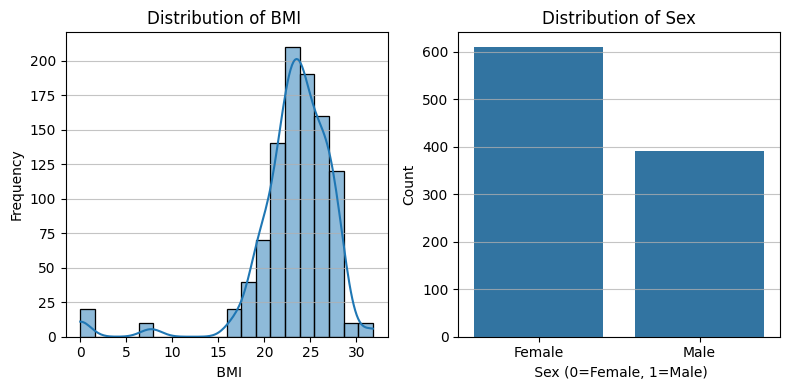

In [ ]:
plt.figure(figsize=(8, 4))

# Plot for  BMI Distribution
plt.subplot(1, 2, 1)
sns.histplot(df['bmi'], kde=True, bins=20)
plt.title('Distribution of BMI ')
plt.xlabel(' BMI')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

# Plot for  Sex Distribution
plt.subplot(1, 2, 2)
sns.countplot(x=df['sex'])
plt.title('Distribution of Sex')
plt.xlabel(' Sex (0=Female, 1=Male)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.xticks([0, 1], ['Female', 'Male'])

plt.tight_layout()
plt.show()

In [ ]:
print("Bmi of ZERO: ", (df["bmi"] == 0).sum())
print(df['bmi'].value_counts().sort_index())

Bmi of ZERO:  20
bmi
0.0     20
7.7     10
16.9    20
18.9    20
19.0    20
19.4    20
19.7    20
19.9    10
20.1    10
20.2    10
20.7    10
20.8    10
21.1    20
21.5    20
21.7    20
21.9    10
22.0    50
22.3    10
22.4    20
22.5    10
22.6    10
22.7    20
22.9    10
23.1    60
23.2    20
23.5    20
23.7    10
23.8    20
23.9    20
24.0    10
24.2    50
24.3    30
24.5    10
24.7    10
24.8    20
24.9    10
25.0    10
25.1    10
25.2    10
25.5    10
25.7    10
25.9    20
26.0    20
26.3    20
26.4    20
26.5    30
26.6    10
26.7    10
26.8    10
27.2    30
27.6    10
27.8    50
28.2    20
28.3    10
28.7    10
31.8    10
Name: count, dtype: int64


###### Exploratory analysis revealed that BMI values were discretized into a limited set of repeated numeric labels rather than forming a continuous distribution. Additionally, anomalous entries such as BMI = 0 and BMI = 7.7 were observed. BMI = 0 was treated as invalid and removed from the dataset, while BMI = 7.7 was retained as a potential extreme outlier.

In [ ]:
df = df[df["bmi"] > 0]
df

,anon_id,sex,bmi,filename
0,5956,0,21.7,5956_8270.jpg
1,5956,0,21.7,5956_1860.jpg
2,5956,0,21.7,5956_6390.jpg
3,5956,0,21.7,5956_6191.jpg
4,5956,0,21.7,5956_6734.jpg
...,...,...,...,...
995,7824,1,19.4,7824_6232.jpg
996,7824,1,19.4,7824_6797.jpg
997,7824,1,19.4,7824_5926.jpg
998,7824,1,19.4,7824_7016.jpg


Let's look at a few images:

In [ ]:
train_dir = '/content/train_images'
test_dir = '/content/test_images'

(224, 224)
<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=224x224 at 0x7D50845F4AA0>


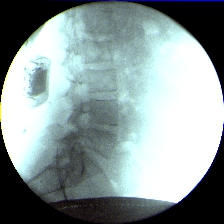

In [ ]:
im = Image.open(f'{train_dir}/{df["filename"][1]}')
print(im.size)
print(im)
im

### 2.1 Resizing
Images are initially resized to a uniform `(128, 128)` resolution. This downsampling is performed to reduce computational load and accelerate training, especially critical during early experimentation or when using limited computational resources.
*While* `(128, 128)` might be small for complex medical imaging tasks, it serves as a rapid prototyping size.


In [ ]:
def resize_folder(in_dir, out_dir, new_size):
    if not os.path.exists(out_dir):
        os.makedirs(out_dir)

    for img_path in tqdm(os.listdir(in_dir)):
        try:
            img = Image.open(f'{in_dir}/{img_path}')
            resized_img = img.resize(new_size)
            out_name = f'{out_dir}/{img_path}'
            resized_img.save(f'{out_dir}/{img_path}', quality=99)
        except:
            print(f"Error processing {img_path}")

In [ ]:
# Define the new size - this is very small and probably unusable but we'll use it for speed
new_size = (128, 128)

# resize
resize_folder(train_dir, '/content/resized/train_images', new_size)
resize_folder(test_dir, '/content/resized/test_images', new_size)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/195 [00:00<?, ?it/s]

(128, 128)
<PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=128x128 at 0x7D507FD11700>


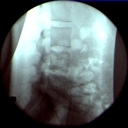

In [ ]:
#checking the new sized image
new_size_img='/content/resized/train_images'
im = Image.open(f'{new_size_img}/{df["filename"][20]}')
print(im.size)
print(im)
im

### 2.2 Dataset creation



In [ ]:
class XrayDataset(Dataset):
    def __init__(self, df_data, img_dir, transform=None):
        self.df_data = df_data # DataFrame containing filenames, sex, and bmi
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.df_data)

    def __getitem__(self, idx):
        row = self.df_data.iloc[idx]
        image_path = os.path.join(self.img_dir, row['filename'])

        #image = Image.open(image_path).convert('L') # our images are greyscale
        image = Image.open(image_path).convert('RGB') #converting greyscale to rgb for pre trained models

        if self.transform: image = self.transform(image)

        # Retrieve sex and bmi.
        sex_label = row['sex']
        bmi_label = row['bmi']

        # Convert to tensor, handling potential NaNs for the test set
        if not pd.isna(sex_label):
            sex_tensor = torch.tensor(sex_label, dtype=torch.float32)
        else:
          sex_tensor = torch.tensor(-1.0, dtype=torch.float32) # Using -1 as a placeholder for unknown sex

        if not pd.isna(bmi_label):
            bmi_tensor = torch.tensor(bmi_label, dtype=torch.float32)
        else:
            bmi_tensor = torch.tensor(-1.0, dtype=torch.float32) # Using -1 as a placeholder for unknown bmi

        return image, (sex_tensor, bmi_tensor)

### 2.3 Normalization
Normalization is crucial for neural network training. It standardizes the input distribution, which helps in faster and more stable convergence of the training process.
for the baseline Model we calculate mean and std from the real image dataset, and when employing pre-trained models like DenseNet or EfficientNet, as these models were originally trained on ImageNet the  standard normalization parameters were applied.

In [ ]:
temp_ds = XrayDataset( df_data=df, img_dir='/content/resized/train_images',
                      transform=Compose([ ToImage(), ToDtype(torch.float32, scale=True) ]) )

loader = DataLoader(temp_ds, batch_size=32, shuffle=False)

num_pixels = 0
sum_pixels = 0.0
sum_sq_pixels = 0.0
print("Calculating mean and std for normalization...")

for imgs, _ in loader:
  imgs = imgs.numpy() # shape: [B, 1, H, W]
  sum_pixels += imgs.sum()
  sum_sq_pixels += (imgs ** 2).sum()
  num_pixels += imgs.size

mean_val = sum_pixels / num_pixels
std_val = np.sqrt(sum_sq_pixels / num_pixels - mean_val ** 2)
print(f"Mean: {mean_val:.4f}, Std: {std_val:.4f}")

Calculating mean and std for normalization...
Mean: 0.4087, Std: 0.3579


### 2.4 BMI normalization

In [ ]:
bmi_mean = df["bmi"].mean()
bmi_std = df["bmi"].std()
print("Bmi mean: ",bmi_mean,"Bmi std :",bmi_std)

df['bmi'] = (df['bmi'] - bmi_mean) / bmi_std

Bmi mean:  23.66938775510204 Bmi std : 3.2519156973088283


### 2.5 Data Augmentations

1. RandomRotation: Introduces rotational invariance, making the model robust to slight angular variations in X-ray images.
2. GaussianNoise: Simulates sensor noise or image artifacts, helping the model become more robust to noisy inputs and real-world imperfections.
3. RandomAutocontrast: Randomly adjusts image contrast to highlight features, making the model less dependent on the original contrast levels and improving its ability to learn from varying image qualities.
4. ColorJitter: Randomly alters brightness and contrast (even for grayscale X-rays) to improve model robustness to varying lighting conditions and image acquisition settings.
5. RandomHorizontalFlip: Creates horizontal mirror images, teaching the model to recognize features regardless of their left-right orientation (assuming such symmetry is valid for X-rays).
6. RandomAffine: Applies random translations, shears, or scaling, making the model more robust to minor positional shifts, distortions, and size variations of anatomical structures.

In [ ]:
transforms_train = Compose([
    ToImage(),

    RandomRotation(5),
    #GaussianNoise(0.01),
    RandomAutocontrast(p=0.2), #instead of jitter

    #ColorJitter(brightness=0.2,contrast=0.2),

    #RandomHorizontalFlip(p=0.5),

    RandomAffine(
      degrees=0.0,
      translate=(0.02, 0.02) ),

    ToDtype(torch.float32, scale=True),

    #for pre trained model we use the models mean and std
    Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])

    #for cnn model
    #Normalize(mean=[mean_val], std=[std_val]) #mean and std calculated from the dataset
])


transforms = Compose([
    ToImage(),                           # Convert a tensor, ndarray, or PIL Image to torchvision.tv_tensors.Image
    ToDtype(torch.float32, scale=True),  # Converts the input to a specific dtype, optionally scaling the values to 0..1 range
    #for cnn model
    #Normalize(mean=[mean_val], std=[std_val]) # Normalization using calculated values

    #for pre trained model we use the models mean and std
    Normalize(mean=[0.485, 0.456, 0.406],std=[0.229, 0.224, 0.225])
])


###2.6 Train-Test-Split

**`Data leakage`**
The dataset contains multiple X-ray images per patient, identified by the anon_id column. If images are randomly split at the row (image) level, images from the same patient may appear in both training and validation sets. This would lead to data leakage, where the model indirectly learns patient-specific features rather than generalizable patterns, resulting in overly optimistic validation performance.

To address this issue, the split was performed at the patient level instead of the image level. First, unique patient IDs were extracted and divided into training and validation groups. Then, all images belonging to each patient were assigned to the corresponding split.

In [ ]:
#DataFrame for test images
test_image_filenames = [f for f in os.listdir('/content/resized/test_images') if f.endswith(('.jpg', '.jpeg', '.png'))]
test_df_data = pd.DataFrame({'filename': test_image_filenames})
#columns for 'sex' and 'bmi' which will be NaN as we don't have labels for test set
test_df_data['sex'] = np.nan
test_df_data['bmi'] = np.nan



# Split the main df into train and validation indices(assigning validation_size=20% of the training)
'''df = df.reset_index(drop=True)
all_indices = list(range(len(df)))

train_ixs, valid_ixs = train_test_split(
    all_indices,
    test_size=0.2,
    random_state=42
)'''

#for preventing data leakage we should split by anon_id so there are no same patient in train and val
unique_ids = df['anon_id'].unique()

train_ids, valid_ids = train_test_split(
    unique_ids,
    test_size=0.2,
    random_state=42
)

train_ixs = df[df['anon_id'].isin(train_ids)].index.tolist()
valid_ixs = df[df['anon_id'].isin(valid_ids)].index.tolist()
# train, validation, and test datasets using the XrayDataset and DataFrames
train_ds = XrayDataset(
    df.loc[train_ixs].reset_index(drop=True),
    '/content/resized/train_images',
    transform=transforms_train
)

valid_ds = XrayDataset(
    df.loc[valid_ixs].reset_index(drop=True),
    '/content/resized/train_images',
    transform=transforms
)

test_ds = XrayDataset(
    test_df_data,
    '/content/resized/test_images',
    transform=transforms
)

print(f"Train dataset will load from: {train_ds.img_dir}, train_Size: {train_ds.__len__()}")
print(f"Validation dataset will load from: {valid_ds.img_dir},validation_Size: {valid_ds.__len__()}")
print(f"Test dataset will load from: {test_ds.img_dir},test_Size: {test_ds.__len__()}")

# Test retrieving an item from train_ds (now returns image and a tuple of labels)
bx, by = train_ds[1]
print(f"Train ds item example: Image shape: {bx.shape}, Labels (sex, bmi): {by}")

Train dataset will load from: /content/resized/train_images, train_Size: 780
Validation dataset will load from: /content/resized/train_images,validation_Size: 200
Test dataset will load from: /content/resized/test_images,test_Size: 195
Train ds item example: Image shape: torch.Size([3, 128, 128]), Labels (sex, bmi): (tensor(1.), tensor(0.3784))


### 2.7 Dataloader and Batch_sizes

In [ ]:
# Create dataloader
bs = 64
train_loader = DataLoader(train_ds, batch_size=bs, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=128, shuffle=False)
test_loader  = DataLoader(test_ds,  batch_size=128, shuffle=False)


##3. Baseline Model

The `CNN` class a custom Convolutional Neural Network architecture designed for multi-task learning (sex classification and BMI regression):

**1. Layers and Backbone (Convolutional Blocks):**

- **Input Layer:** Assumes a single-channel input (greyscale image), which is why the first convolutional layer `self.conv1` takes 1 input channel.
- **Convolutional Layers:** The network consists of 8 convolutional layers (`conv1` through `conv8`). Each `nn.Conv2d` layer has a kernel size of 3, a stride of 1, and padding of 1, meaning it preserves the spatial dimensions of its input.
  - The number of output channels progressively increases: `1 -> 16 -> 16 -> 32 -> 32 -> 64 -> 64 -> 128 -> 128`.
- **Batch Normalization:** Each convolutional layer is immediately followed by `nn.BatchNorm2d` (`bn1` through `bn8`), which helps in stabilizing and accelerating the training process.
- **Activation Function:** The `relu` activation function (`f.relu`) is applied after each batch normalization.
- **Max Pooling:** `nn.MaxPool2d(2, 2)` layers (`self.pool`) are applied after every two convolutional layers. This operation halves the spatial dimensions (height and width) of the feature maps, reducing computational complexity and extracting more robust features.

**2. Global Average Pooling (`GAP`):**

- After the last convolutional block, `self.gap = nn.AdaptiveAvgPool2d(1)` is applied. This layer takes the average of each feature map across its spatial dimensions, resulting in a `(batch_size, channels)` tensor. For instance, the 128-channel output from the last convolutional block is reduced to a `(batch_size, 128)` tensor. This is a common practice to reduce the number of parameters in the subsequent fully connected layers and make the model more robust to spatial variations.
- `torch.flatten(x, 1)` is then used to flatten the tensor into a 1D vector suitable for the fully connected layers.

**3. Fully Connected Layers (`FC`):**

- **Dropout:** A `self.dropout = nn.Dropout(0.4)` layer is applied before the shared fully connected layer to prevent overfitting by randomly setting a fraction of input units to 0 at each update during training.
- **Shared Fully Connected Layer:** A `self.fc = nn.Linear(128, 64)` layer acts as a shared feature extractor after the convolutional and pooling stages. It transforms the 128 features from the GAP layer into 64 features.

**4. Task-Specific Heads:**

- **Sex Head:** `self.sex_head = nn.Linear(64, 1)` is a linear layer for binary sex classification. It takes the 64 features from the shared FC layer and outputs a single value (logits for sigmoid activation in the loss function).
- **BMI Head:** `self.bmi_head = nn.Linear(64, 1)` is another linear layer for BMI regression. It also takes the 64 features and outputs a single continuous value for BMI prediction.

**5. Forward Pass**


In [ ]:
class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 16, 3, 1, 1)
        self.bn1 = nn.BatchNorm2d(16)

        self.conv2 = nn.Conv2d(16, 16, 3, 1, 1)
        self.bn2 = nn.BatchNorm2d(16)

        self.conv3 = nn.Conv2d(16, 32, 3, 1, 1)
        self.bn3 = nn.BatchNorm2d(32)

        self.conv4 = nn.Conv2d(32, 32, 3, 1, 1)
        self.bn4 = nn.BatchNorm2d(32)

        self.conv5 = nn.Conv2d(32, 64, 3, 1, 1)
        self.bn5 = nn.BatchNorm2d(64)

        self.conv6 = nn.Conv2d(64, 64, 3, 1, 1)
        self.bn6 = nn.BatchNorm2d(64)

        self.conv7 = nn.Conv2d(64, 128, 3, 1, 1)
        self.bn7 = nn.BatchNorm2d(128)

        self.conv8 = nn.Conv2d(128, 256, 3, 1, 1)
        self.bn8 = nn.BatchNorm2d(256)

        self.pool = nn.MaxPool2d(2, 2)
        self.gap = nn.AdaptiveAvgPool2d(1)

        self.fc = nn.Sequential(
                      nn.Linear(256, 100),
                      nn.ReLU(),
                      nn.Dropout(0.3)
                  )

        self.sex_head = nn.Linear(100, 1)
        self.bmi_head = nn.Linear(100, 1)

    def forward(self, x):

        x = f.relu(self.bn1(self.conv1(x)))
        x = self.pool(f.relu(self.bn2(self.conv2(x))))

        x = f.relu(self.bn3(self.conv3(x)))
        x = self.pool(f.relu(self.bn4(self.conv4(x))))

        x = f.relu(self.bn5(self.conv5(x)))
        x = self.pool(f.relu(self.bn6(self.conv6(x))))

        x = f.relu(self.bn7(self.conv7(x)))
        x = self.pool(f.relu(self.bn8(self.conv8(x))))



        x = self.gap(x)
        x = torch.flatten(x, 1)

        x = self.fc(x)

        sex = self.sex_head(x)
        bmi = self.bmi_head(x)

        return sex, bmi

## 4. State-of-the-Art Models


**Pre Trained Models:**
1.  **ResNet (Residual Networks):** is a convolutional neural network that introduces residual connections (skip connections). These connections allow gradients to flow through deeper layers more effectively, mitigating the vanishing gradient problem.

  * `Advantages`

    Relatively small and efficient.

    Easier to train on small datasets.

    Good transfer learning performance.

    Lower risk of overfitting compared to larger architectures.

* `Potential limitations`

    Lower representational capacity than deeper networks.

    May miss subtle image patterns captured by larger models.

* `Suitability for this task`

    Appropriate because the dataset contains only about 1000 X-ray images.

    Provides a strong balance between accuracy and generalization.

    Often serves as an excellent transfer-learning baseline.

2.  **DenseNet (Densely Connected Convolutional Networks):** Features direct connections from any layer to all subsequent layers, promoting feature reuse and reducing the number of parameters.

* `Advantages`

    Relatively small and efficient.

    Easier to train on small datasets.

    Good transfer learning performance.

    Lower risk of overfitting compared to larger architectures.

* `Potential limitations`

    Lower representational capacity than deeper networks.

    May miss subtle image patterns captured by larger models.

* `Suitability for this task`

    Appropriate because the dataset contains only about 1000 X-ray images.

    Provides a strong balance between accuracy and generalization.

    Often serves as an excellent transfer-learning baseline.
3.  **EfficientNet:** A family of models developed using neural architecture search (NAS) that uniformly scales all dimensions of depth, width, and resolution for better efficiency and accuracy.

* `Advantages`

    Excellent accuracy-to-parameter ratio.

    Strong performance on small and medium datasets.

    Efficient computation.
    Reduced overfitting risk.

* `Potential limitations`

    More complex architecture.

    Slightly slower inference than ResNet18.

* `Suitability for this task`

    Particularly attractive for medical imaging.

    Good balance between efficiency and representation power.

    Often performs very well when transfer learning is used on limited datasets.

**Model Complexity :**

| Model           | Parameters | FLOPs (224×224) | Size     |
| --------------- | ---------- | --------------- | -------- |
| ResNet18        | ~11.7 M    | ~1.8 GFLOPs     | Small    |
| DenseNet121     | ~8.0 M     | ~2.9 GFLOPs     | Medium   |
| EfficientNet-B0 | ~5.3 M     | ~0.39 GFLOPs    | Smallest |



###4.1 Model-1 : ResNet



The `ResNet` class utilizes a pre-trained ResNet18 model from `torchvision.models` as its backbone for feature extraction, adapting it for multi-task learning (sex classification and BMI regression).




In [ ]:
class ResNet(nn.Module):
    def __init__(self):
        super(ResNet, self).__init__()

        # Load pretrained ResNet18
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

        # Change first conv layer for grayscale input
        '''self.backbone.conv1 = nn.Conv2d(
            3, 64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )'''

        # Remove original classifier
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()

        # Shared feature dimension = 512
        #if we use shared fc layer then seprated for sex and bmi
        self.shared = nn.Sequential(
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.5)
        )

        # Sex head (binary classification) without shared fc layer
        '''self.sex_head = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1)
        )

        # BMI head (regression)
        self.bmi_head = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 1)
        )'''


        self.sex_head = nn.Linear(128, 1)
        self.bmi_head = nn.Linear(128, 1)

    def forward(self, x):
        features = self.backbone(x)
        #if used shared fc layer
        features = self.shared(features)

        sex_out = self.sex_head(features)
        bmi_out = self.bmi_head(features)

        return sex_out, bmi_out

###4.2 Model-2 : DenseNet

The `DenseNet` class utilizes a pre-trained DenseNet121 model from `torchvision.models` as its backbone for feature extraction, adapting it for multi-task learning (sex classification and BMI regression).



In [ ]:
class DenseNet(nn.Module):
    def __init__(self):
        super(DenseNet, self).__init__()

        self.backbone = models.densenet121(
            weights=models.DenseNet121_Weights.DEFAULT
        )

        # Modify first conv for grayscale
        '''self.backbone.features.conv0 = nn.Conv2d(
            3, 64,
            kernel_size=7,
            stride=2,
            padding=3,
            bias=False
        )'''

        in_features = self.backbone.classifier.in_features
        self.backbone.classifier = nn.Identity()

        # Sex head
        '''self.sex_head = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(0.7),
            nn.Linear(128, 1)
        )

        # BMI head
        self.bmi_head = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, 1)
        )'''
         #if we use shared fc layer then seprated for sex and bmi
        self.shared = nn.Sequential(
        nn.Linear(in_features, 128),
        nn.ReLU(),
        nn.Dropout(0.4)
        )

        self.sex_head = nn.Linear(128, 1)
        self.bmi_head = nn.Linear(128, 1)

    def forward(self, x):
        features = self.backbone(x)

        #if used shared fc layer
        features = self.shared(features)

        sex_out = self.sex_head(features)
        bmi_out = self.bmi_head(features)

        return sex_out, bmi_out

###4.3 Model-3 : EfficientNet

The `EfficientNetMultiTask` class leverages a pre-trained EfficientNet-B0 model from `torchvision.models` as its backbone for feature extraction. This architecture is designed for multi-task learning, specifically sex classification and BMI regression.

In [ ]:
class EfficientNetMultiTask(nn.Module):

    def __init__(self):
        super(EfficientNetMultiTask, self).__init__()

        # Load pretrained EfficientNet-B0
        weights = EfficientNet_B0_Weights.DEFAULT
        self.backbone = models.efficientnet_b0(weights=weights)


        # Remove original classifier
        in_features = self.backbone.classifier[1].in_features

        # Replace original classifier with identity
        self.backbone.classifier = nn.Identity()

        # Shared multitask feature layer
        self.shared = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.SiLU(),
            nn.Dropout(0.4),


        )

        # Sex classification head
        self.sex_head = nn.Linear(128, 1)

        # BMI regression head
        self.bmi_head = nn.Linear(128, 1)

        #if we use separate heads for sex,bmi
        # Sex head
        '''self.sex_head = nn.Sequential(

            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.6),
            nn.Linear(512, 128),
            nn.ReLU(),
            #nn.Dropout(0.6),
            nn.Linear(128, 1)
        )

        # BMI head
        self.bmi_head = nn.Sequential(
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )'''

    def forward(self, x):
        features = self.backbone(x)

        #if used shared fc layer
        features = self.shared(features)

        sex_out = self.sex_head(features)
        bmi_out = self.bmi_head(features)

        return sex_out, bmi_out

##5. Model Initials-Training Loop-Experiments

In [ ]:
# train on GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

#model = CNN()
model = EfficientNetMultiTask()
model.to(device)

print(model)

for param in model.backbone.parameters():
    param.requires_grad = False

cuda
EfficientNetMultiTask(
  (backbone): EfficientNet(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): SiLU(inplace=True)
      )
      (1): Sequential(
        (0): MBConv(
          (block): Sequential(
            (0): Conv2dNormActivation(
              (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
              (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
              (2): SiLU(inplace=True)
            )
            (1): SqueezeExcitation(
              (avgpool): AdaptiveAvgPool2d(output_size=1)
              (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
              (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
              (activation): SiLU(inplace=True)
      

`loss functions` , `Optimizer` , `scheduler`




In [ ]:
#there is a class imbalance in the df that might bias the training
pos_weight = torch.tensor([590/390]).to(device) #we can pass it to sex_criterion

sex_criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
bmi_criterion = nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=8
)

In [ ]:
train_sex_losses = []
valid_sex_losses = []
train_bmi_losses = []
valid_bmi_losses = []
train_accuracies = []
valid_accuracies = []
x_axis = []

print("Metric lists initialized for continuous plotting and training.")

Metric lists initialized for continuous plotting and training.


The `one_epoch` function handles a single pass over the dataset (either training or validation). It computes the sex and BMI losses, tracks accuracy for sex prediction, and performs backpropagation and optimization if an optimizer is provided (for training mode).

In [ ]:
def one_epoch(model, loader, sex_criterion, bmi_criterion, optimizer=None):
    device = next(model.parameters()).device

    if optimizer is None:
        model.eval()
    else:
        model.train()

    running_sex_loss = 0.0
    running_bmi_loss = 0.0
    total_samples = 0
    correct_sex_predictions = 0

    all_sex_labels = []
    all_sex_outputs = []

    with torch.set_grad_enabled(optimizer is not None):

        for images, (sex_labels, bmi_labels) in loader:
            images = images.to(device)
            sex_labels = sex_labels.to(device)
            bmi_labels = bmi_labels.to(device)

            # Forward pass
            sex_outputs, bmi_outputs = model(images)

            # Calculate individual losses
            sex_loss = sex_criterion(sex_outputs, sex_labels.unsqueeze(1))
            bmi_loss = bmi_criterion(bmi_outputs, bmi_labels.unsqueeze(1))
            alpha = 0.7
            beta = 0.3
            # Combine losses (e.g., simple sum or weighted sum)
            #total_loss = sex_loss + bmi_loss # You can add weights here if desired
            total_loss =  (sex_loss * alpha) + (bmi_loss * beta)
            # Backward and optimize
            if optimizer is not None:
                optimizer.zero_grad()
                total_loss.backward()
                optimizer.step()

            total_samples += images.size(0)
            running_sex_loss += sex_loss.item() * images.size(0)
            running_bmi_loss += bmi_loss.item() * images.size(0)

            # Store predictions and labels for AUC calculation
            all_sex_labels.extend(sex_labels.detach().cpu().numpy())
            all_sex_outputs.extend(torch.sigmoid(sex_outputs).detach().cpu().numpy())


            # Calculate accuracy for sex prediction
            predicted_sex = (torch.sigmoid(sex_outputs) > 0.50).float()
            correct_sex_predictions += (predicted_sex == sex_labels.unsqueeze(1)).sum().item()

    epoch_sex_loss = running_sex_loss / total_samples
    epoch_bmi_loss = running_bmi_loss / total_samples
    epoch_sex_accuracy = correct_sex_predictions / total_samples

    return epoch_sex_loss, epoch_bmi_loss, epoch_sex_accuracy, np.array(all_sex_labels), np.array(all_sex_outputs)


In [ ]:
# training loop

num_epochs=120
start_epoch_for_this_run = len(x_axis)


for i in range(num_epochs): # Loop for the number of epochs requested for this run
    # Calculate the absolute epoch number for plotting, ensuring it's continuous
    absolute_epoch_number = start_epoch_for_this_run + i + 1
    x_axis.append(absolute_epoch_number)

    if i == 20:
      print("Unfreezing backbone...")

      for param in model.backbone.parameters():
            param.requires_grad = True

      optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=1e-5,
            weight_decay=1e-6
        )
      scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode='min',
            factor=0.5,
            patience=8
        )


    # Pass both criteria to one_epoch
    train_sex_loss, train_bmi_loss, train_accuracy, train_sex_labels, train_sex_outputs = one_epoch(model, train_loader, sex_criterion, bmi_criterion, optimizer)
    valid_sex_loss, valid_bmi_loss, valid_accuracy, valid_sex_labels, valid_sex_outputs = one_epoch(model, valid_loader, sex_criterion, bmi_criterion)

    scheduler.step(valid_bmi_loss)



    train_sex_losses.append(train_sex_loss)
    valid_sex_losses.append(valid_sex_loss)
    train_bmi_losses.append(train_bmi_loss)
    valid_bmi_losses.append(valid_bmi_loss)
    train_accuracies.append(train_accuracy)
    valid_accuracies.append(valid_accuracy)

    if (i + 1) % 10 == 0 or i == 0:
      print(f'Epoch [{absolute_epoch_number:02d}/{start_epoch_for_this_run + num_epochs}], ')
      print(f'  Train Sex Loss: {train_sex_loss:.4f}, Train BMI Loss: {train_bmi_loss:.4f}, Train Accuracy: {train_accuracy:.4f}')
      print(f'  Valid Sex Loss: {valid_sex_loss:.4f}, Valid BMI Loss: {valid_bmi_loss:.4f}, Valid Accuracy: {valid_accuracy:.4f}')

Epoch [01/120], 
  Train Sex Loss: 0.8284, Train BMI Loss: 0.3915, Train Accuracy: 0.5923
  Valid Sex Loss: 0.8214, Valid BMI Loss: 0.3314, Valid Accuracy: 0.6200
Epoch [10/120], 
  Train Sex Loss: 0.6291, Train BMI Loss: 0.2917, Train Accuracy: 0.7910
  Valid Sex Loss: 0.6870, Valid BMI Loss: 0.2706, Valid Accuracy: 0.7000
Epoch [20/120], 
  Train Sex Loss: 0.4797, Train BMI Loss: 0.2642, Train Accuracy: 0.8423
  Valid Sex Loss: 0.5994, Valid BMI Loss: 0.2476, Valid Accuracy: 0.7900
Unfreezing backbone...
Epoch [30/120], 
  Train Sex Loss: 0.3157, Train BMI Loss: 0.2396, Train Accuracy: 0.9154
  Valid Sex Loss: 0.5252, Valid BMI Loss: 0.2270, Valid Accuracy: 0.8050
Epoch [40/120], 
  Train Sex Loss: 0.1850, Train BMI Loss: 0.2159, Train Accuracy: 0.9628
  Valid Sex Loss: 0.4688, Valid BMI Loss: 0.2189, Valid Accuracy: 0.8200
Epoch [50/120], 
  Train Sex Loss: 0.1258, Train BMI Loss: 0.2038, Train Accuracy: 0.9821
  Valid Sex Loss: 0.4395, Valid BMI Loss: 0.2105, Valid Accuracy: 0.8300

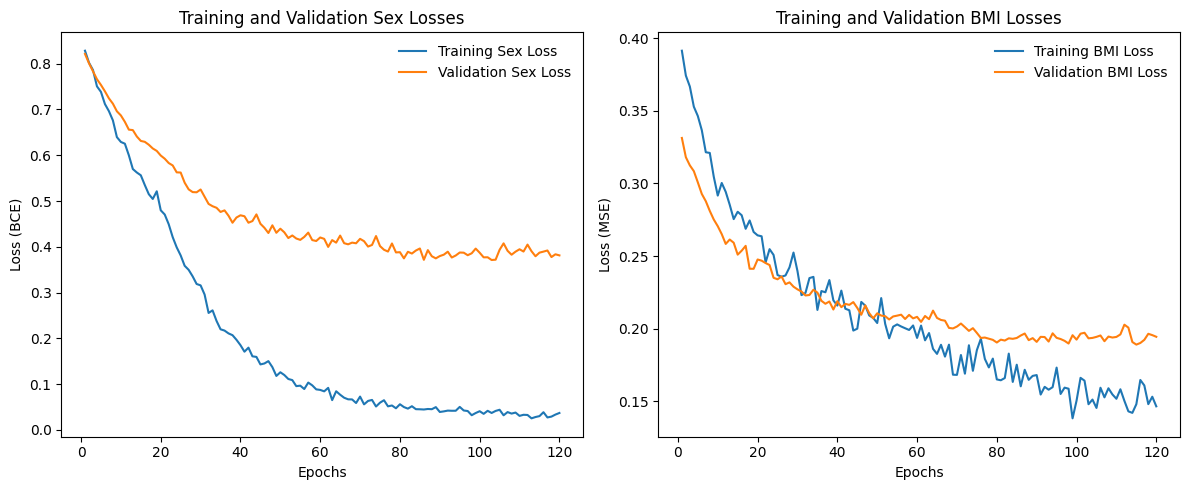

In [ ]:
num_epochs_completed = len(train_sex_losses)
x_axis_for_plotting = x_axis[:num_epochs_completed]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(x_axis_for_plotting, train_sex_losses, label="Training Sex Loss")
plt.plot(x_axis_for_plotting, valid_sex_losses, label="Validation Sex Loss")
plt.legend(frameon=False)
plt.title('Training and Validation Sex Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss (BCE)')

plt.subplot(1, 2, 2)
plt.plot(x_axis_for_plotting, train_bmi_losses, label="Training BMI Loss")
plt.plot(x_axis_for_plotting, valid_bmi_losses, label="Validation BMI Loss")
plt.legend(frameon=False)
plt.title('Training and Validation BMI Losses')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')

plt.tight_layout()
plt.show()

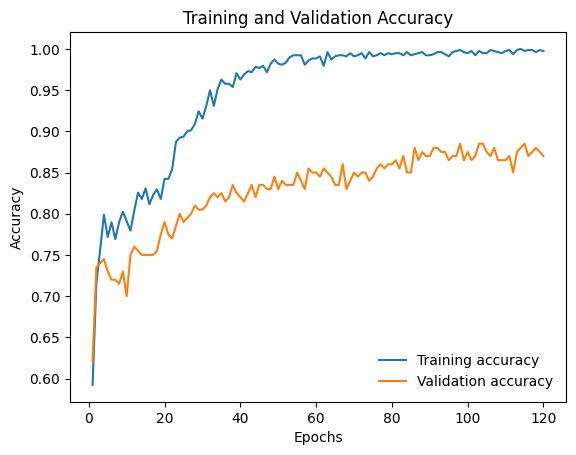

In [ ]:
plt.plot(x_axis_for_plotting ,train_accuracies, label="Training accuracy")
plt.plot( x_axis_for_plotting,valid_accuracies, label="Validation accuracy")
plt.legend(frameon=False)
#plt.ylim(0, 1)
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#plt.savefig("/content/drive/MyDrive/Colab Notebooks/nn.png")
plt.show()

### 5.1 Experimentation for Model Improvememt


#### Experiment 10: Using Cross-Validation for Model


##### Hypothesis
Implementing K-Fold Cross-Validation will provide a more robust and reliable estimate of the model's performance on unseen data by training and evaluating the model on multiple data partitions. Ensembling the predictions from models trained across different folds should reduce prediction variance and improve overall accuracy.

##### Implementation Details
The training process was adapted to use 5-Fold Cross-Validation. For each fold, a model was trained, and its weights were saved. Predictions on the test set were then ensembled by averaging the outputs of all 5 models.

##### Results Structure
Kaggle Private Score: 0.4862
Kaggle Public Score: 0.4506

In [ ]:
num_folds = 5
kf = KFold(n_splits=num_folds, shuffle=True, random_state=42)

cv_num_epochs = 80

# Lists to store results from each fold
fold_valid_sex_losses = []
fold_valid_bmi_losses = []
fold_valid_accuracies = []

# List to store paths of saved models
saved_model_paths = []

print(f"Starting {num_folds}-Fold Cross-Validation with {cv_num_epochs} epochs per fold...")

for fold, (train_idx, val_idx) in enumerate(kf.split(unique_ids)):
    print(f"\n=== Starting Fold {fold+1}/{num_folds} ===")

    # Get unique IDs for this fold's train and validation sets
    train_fold_ids = unique_ids[train_idx]
    valid_fold_ids = unique_ids[val_idx]

    # Filter the main DataFrame `df` based on these IDs
    train_df_fold = df[df['anon_id'].isin(train_fold_ids)].reset_index(drop=True)
    valid_df_fold = df[df['anon_id'].isin(valid_fold_ids)].reset_index(drop=True)

    # Create datasets for the current fold
    train_ds_fold = XrayDataset(
        train_df_fold,
        '/content/resized/train_images',
        transform=transforms_train

    )
    valid_ds_fold = XrayDataset(
        valid_df_fold,
        '/content/resized/train_images',
        transform=transforms

    )

    # Create dataloaders for the current fold
    train_loader_fold = DataLoader(train_ds_fold, batch_size=64, shuffle=True)
    valid_loader_fold = DataLoader(valid_ds_fold, batch_size=128, shuffle=False)

    print(f"Fold {fold+1} Train dataset size: {len(train_ds_fold)}")
    print(f"Fold {fold+1} Validation dataset size: {len(valid_ds_fold)}")

    # --- Re-initialize model, optimizer, and scheduler for each fold ---
    model_fold = CNN() # Changed to CNN model
    model_fold.to(device)

    # For CNN, all parameters are trained from the start, no backbone to freeze/unfreeze
    optimizer_fold = torch.optim.AdamW(
        model_fold.parameters(),
        lr=1e-4, # Initial learning rate
        weight_decay=1e-5
    )
    scheduler_fold = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer_fold,
        mode='min',
        factor=0.5,
        patience=8
    )

    # --- Training loop for the current fold ---
    for epoch in range(cv_num_epochs):
        # Removed unfreezing logic as it's not applicable to custom CNN

        train_sex_loss, train_bmi_loss, train_accuracy, _, _ = one_epoch(
            model_fold, train_loader_fold, sex_criterion, bmi_criterion, optimizer_fold
        )
        valid_sex_loss, valid_bmi_loss, valid_accuracy, _, _ = one_epoch(
            model_fold, valid_loader_fold, sex_criterion, bmi_criterion
        )

        scheduler_fold.step(valid_bmi_loss)

        if (epoch + 1) % (cv_num_epochs // 2) == 0 or epoch == 0:
            print(f'  Fold {fold+1}, Epoch [{epoch+1}/{cv_num_epochs}],\n '
                  f'Train Sex Loss: {train_sex_loss:.4f}, Train BMI Loss: {train_bmi_loss:.4f}, Train Acc: {train_accuracy:.4f}\n '
                  f'Valid Sex Loss: {valid_sex_loss:.4f}, Valid BMI Loss: {valid_bmi_loss:.4f}, Valid Acc: {valid_accuracy:.4f}\n')

    # Store final validation metrics for this fold
    fold_valid_sex_losses.append(valid_sex_loss)
    fold_valid_bmi_losses.append(valid_bmi_loss)
    fold_valid_accuracies.append(valid_accuracy)

    # Save the model state dict for this fold
    model_path = f'/content/cnn_fold_{fold+1}.pth'
    torch.save(model_fold.state_dict(), model_path)
    saved_model_paths.append(model_path)
    print(f"Saved model for Fold {fold+1} to {model_path}")

print("\n=== K-Fold Cross-Validation Complete ===")
print(f"Average Validation Sex Loss across {num_folds} folds: {np.mean(fold_valid_sex_losses):.4f}")
print(f"Average Validation BMI Loss across {num_folds} folds: {np.mean(fold_valid_bmi_losses):.4f}")
print(f"Average Validation Accuracy across {num_folds} folds: {np.mean(fold_valid_accuracies):.4f}")


Starting 5-Fold Cross-Validation with 80 epochs per fold...

=== Starting Fold 1/5 ===
Fold 1 Train dataset size: 780
Fold 1 Validation dataset size: 200
  Fold 1, Epoch [1/80],
 Train Sex Loss: 0.6881, Train BMI Loss: 0.4008, Train Acc: 0.5397
 Valid Sex Loss: 0.6887, Valid BMI Loss: 0.3493, Valid Acc: 0.6000

  Fold 1, Epoch [40/80],
 Train Sex Loss: 0.1200, Train BMI Loss: 0.1637, Train Acc: 0.9744
 Valid Sex Loss: 0.2679, Valid BMI Loss: 0.1803, Valid Acc: 0.9050

  Fold 1, Epoch [80/80],
 Train Sex Loss: 0.0568, Train BMI Loss: 0.1198, Train Acc: 0.9974
 Valid Sex Loss: 0.2107, Valid BMI Loss: 0.1621, Valid Acc: 0.9100

Saved model for Fold 1 to /content/cnn_fold_1.pth

=== Starting Fold 2/5 ===
Fold 2 Train dataset size: 780
Fold 2 Validation dataset size: 200
  Fold 2, Epoch [1/80],
 Train Sex Loss: 0.6837, Train BMI Loss: 0.3520, Train Acc: 0.5692
 Valid Sex Loss: 0.6831, Valid BMI Loss: 0.5038, Valid Acc: 0.6500

  Fold 2, Epoch [40/80],
 Train Sex Loss: 0.1019, Train BMI Loss

#### Experiment 10.1:
Making Predictions on the Test Set using Ensembling from K-Fold CV

Now that we have trained and saved a separate model for each fold during cross-validation, we can use an ensembling approach to make predictions on the hold-out test set. This involves:

1.  **Loading each trained model**: Each model (`CNN` instance) is re-initialized and its saved weights are loaded.
2.  **Collecting predictions from each model**: Each model predicts sex and BMI for the entire test set.
3.  **Averaging predictions**: The raw sex logits and BMI predictions from all models are averaged. For sex, the average logits are then passed through a sigmoid function. For BMI, the averaged predictions are denormalized.

In [ ]:
# List to store predictions from each fold's model
all_fold_sex_preds = []
all_fold_bmi_preds = []

print(f"Loading {len(saved_model_paths)} models and making predictions on the test set...")

for i, model_path in enumerate(saved_model_paths):
    print(f"\nLoading model from {model_path} (Fold {i+1})...")

    # Re-initialize the model architecture
    model_fold = CNN()
    model_fold.to(device)

    # Load the saved state dictionary
    model_fold.load_state_dict(torch.load(model_path))
    model_fold.eval() # Set to evaluation mode

    fold_sex_preds = []
    fold_bmi_preds = []

    with torch.no_grad():
        for images, _ in test_loader:
            images = images.to(device)
            sex_outputs, bmi_outputs = model_fold(images)

            # Collect raw logits for sex and raw predictions for BMI
            fold_sex_preds.extend(sex_outputs.cpu().numpy().flatten())
            fold_bmi_preds.extend(bmi_outputs.cpu().numpy().flatten())

    all_fold_sex_preds.append(np.array(fold_sex_preds))
    all_fold_bmi_preds.append(np.array(fold_bmi_preds))

# Convert lists of arrays to a single numpy array
all_fold_sex_preds = np.array(all_fold_sex_preds) # Shape: (num_folds, num_test_samples)
all_fold_bmi_preds = np.array(all_fold_bmi_preds) # Shape: (num_folds, num_test_samples)

# Ensembling: Average the predictions across all folds
ensembled_sex_logits = np.mean(all_fold_sex_preds, axis=0)
ensembled_bmi_predictions_normalized = np.mean(all_fold_bmi_preds, axis=0)

# Post-processing for ensembled predictions
# Sex: Apply sigmoid and threshold
ensembled_sex_pred = (torch.sigmoid(torch.tensor(ensembled_sex_logits)) > 0.5).float().numpy()

# BMI: Denormalize
ensembled_bmi_pred = ensembled_bmi_predictions_normalized * bmi_std + bmi_mean

# Round BMI predictions as before
ensembled_bmi_pred = ensembled_bmi_pred.round(3)

# Get the filenames for the test set from the DataFrame used to create test_ds
hold_out_filenames = test_df_data['filename'].tolist()

# Create a DataFrame for submission
submission_df_cv = pd.DataFrame({'filename': hold_out_filenames, 'sex': ensembled_sex_pred, 'bmi': ensembled_bmi_pred})

# Save the submission file
submission_df_cv.to_csv('submission_cv_ensembled.csv', index=False)

print("Ensembled submission file created successfully!")
print(submission_df_cv.head())

Loading 5 models and making predictions on the test set...

Loading model from /content/cnn_fold_1.pth (Fold 1)...

Loading model from /content/cnn_fold_2.pth (Fold 2)...

Loading model from /content/cnn_fold_3.pth (Fold 3)...

Loading model from /content/cnn_fold_4.pth (Fold 4)...

Loading model from /content/cnn_fold_5.pth (Fold 5)...
Ensembled submission file created successfully!
        filename  sex     bmi
0  1148_7947.jpg  1.0  21.570
1  3528_8392.jpg  0.0  24.211
2  5828_9302.jpg  0.0  26.632
3  9029_2398.jpg  0.0  25.356
4  3338_4713.jpg  1.0  22.969


In [ ]:
print(submission_df_cv['sex'].value_counts())
print(submission_df_cv['bmi'].value_counts())
submission_df_cv.describe()
print(len(submission_df_cv['bmi']))

sex
1.0    110
0.0     85
Name: count, dtype: int64
bmi
26.632    2
24.499    2
27.291    2
24.425    2
25.294    2
         ..
27.299    1
24.755    1
25.219    1
26.989    1
26.859    1
Name: count, Length: 190, dtype: int64
195


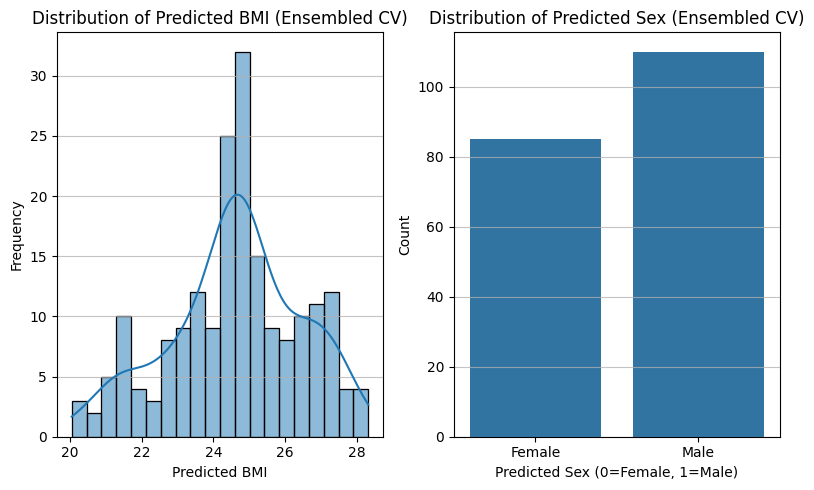

In [ ]:
plt.figure(figsize=(8, 5))

# Plot for Predicted BMI Distribution (Ensembled CV)
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.histplot(submission_df_cv['bmi'], kde=True, bins=20)
plt.title('Distribution of Predicted BMI (Ensembled CV)')
plt.xlabel('Predicted BMI')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

# Plot for Predicted Sex Distribution (Ensembled CV)
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.countplot(x=submission_df_cv['sex'])
plt.title('Distribution of Predicted Sex (Ensembled CV)')
plt.xlabel('Predicted Sex (0=Female, 1=Male)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.xticks([0, 1], ['Female', 'Male'])

plt.tight_layout()
plt.show()

## 6.Model Evaluation and Explainability


###6.1  performance evaluation on validation set

Let's evaluate the model's sex classification performance on the validation set using key metrics such as accuracy, precision, recall, F1-score, and a confusion matrix. These metrics provide a deeper insight into the model's strengths and weaknesses beyond just overall accuracy.

In [ ]:
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():

    for images, (sex_labels, bmi_labels) in valid_loader:

        images = images.to(device)

        sex_outputs, _ = model(images)

        preds = (torch.sigmoid(sex_outputs) > 0.50).float()

        all_preds.extend(preds.cpu().numpy().flatten())

        all_labels.extend(sex_labels.numpy())

acc = accuracy_score(all_labels, all_preds)

precision = precision_score(all_labels, all_preds)

recall = recall_score(all_labels, all_preds)

f1 = f1_score(all_labels, all_preds)

# Calculate misclassified count
misclassified_sex_count = sum(1 for true, pred in zip(all_labels, all_preds) if true != pred)

print(f"\n--- Validation Sex Classification Metrics ---")
print(f"Accuracy: {acc:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Misclassified Sex Count: {misclassified_sex_count}")



--- Validation Sex Classification Metrics ---
Accuracy: 0.8700
Precision: 0.8140
Recall: 0.8750
F1-Score: 0.8434
Misclassified Sex Count: 26


[[104  16]
 [ 10  70]]


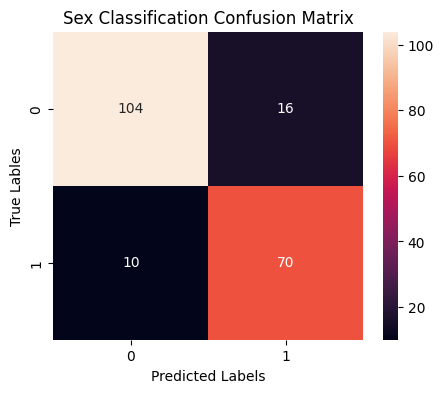

In [ ]:
cm = confusion_matrix(all_labels, all_preds)

print(cm)

plt.figure(figsize=(5,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d'
)

plt.xlabel("Predicted Labels")
plt.ylabel("True Lables")
plt.title("Sex Classification Confusion Matrix")
plt.show()

### Interpretation of Metrics:

*   **Accuracy:** The proportion of correctly classified instances out of the total instances. A high accuracy is generally good, but it can be misleading if the classes are imbalanced.
*   **Precision:** The proportion of true positive predictions among all positive predictions. It answers: "Of all the instances predicted as positive, how many are actually positive?" High precision means fewer false positives.
*   **Recall (Sensitivity):** The proportion of true positive predictions among all actual positive instances. It answers: "Of all the actual positive instances, how many did the model correctly identify?" High recall means fewer false negatives.
*   **F1-Score:** The harmonic mean of precision and recall. It provides a single score that balances both precision and recall, especially useful when there's an uneven class distribution.
*   **Confusion Matrix:** A table that visualizes the performance of a classification model. Each row represents the instances in an actual class, while each column represents the instances in a predicted class. It helps to quickly see true positives, true negatives, false positives, and false negatives.

###6.2 Grad-CAM Visualization

Let's implement Grad-CAM to visualize what parts of the image are most important for the model's predictions.

In [ ]:
model.eval()

worst_samples = []

with torch.no_grad():

    for images, (sex_labels, bmi_labels) in valid_loader:

        images = images.to(device)

        sex_labels = sex_labels.to(device)
        bmi_labels = bmi_labels.to(device)

        sex_outputs, bmi_outputs = model(images)

        sex_loss = torch.nn.functional.binary_cross_entropy_with_logits(
            sex_outputs,
            sex_labels.unsqueeze(1)
        )

        bmi_loss = torch.nn.functional.smooth_l1_loss(
            bmi_outputs,
            bmi_labels.unsqueeze(1),
            reduction='none'
        )

        probs = (torch.sigmoid(sex_outputs) > 0.50).float()

        sex_errors = torch.abs(
            probs.squeeze() - sex_labels
        )

        sample_losses = (
            sex_errors +
            bmi_loss.squeeze()
        )

        for i in range(images.size(0)):

            worst_samples.append({

                'loss': sample_losses[i].item(),

                'image': images[i].cpu(),

                'sex_true': sex_labels[i].item(),

                'sex_pred': probs[i].item(),

                'bmi_true': bmi_labels[i].item(),

                'bmi_pred': bmi_outputs[i].item()

            })

worst_samples = sorted(
    worst_samples,
    key=lambda x: x['loss'],
    reverse=True
)

top5 = worst_samples[:5]

print("Collected top 5 highest-loss samples")

target_layers = [
    model.backbone.features[-1]   #efficient net
    #model.conv8  #cnn
    #model.backbone.layer4[-1]    #resnet
    #model.backbone.features.denseblock4  #dense net
]

# Define a wrapper for the model to expose only sex outputs for GradCAM
class SexPredictionWrapper(torch.nn.Module):
    def __init__(self, original_model):
        super().__init__()
        self.original_model = original_model

    def forward(self, x):
        sex_outputs, _ = self.original_model(x)
        return sex_outputs

# Instantiate the wrapper
sex_cam_model = SexPredictionWrapper(model)

cam = GradCAM(
    model=sex_cam_model, # Use the wrapped model here
    target_layers=target_layers
)

Collected top 5 highest-loss samples


True Sex=0.0                Pred Sex=1.0
True BMI=1.21               Pred BMI=-0.43
Loss=2.140


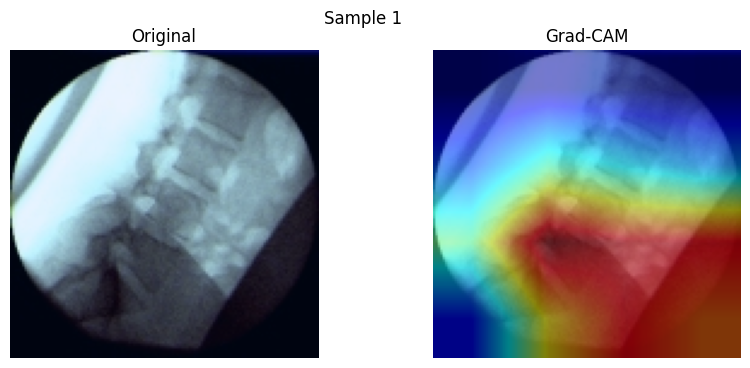

True Sex=0.0                Pred Sex=1.0
True BMI=1.21               Pred BMI=-0.03
Loss=1.736


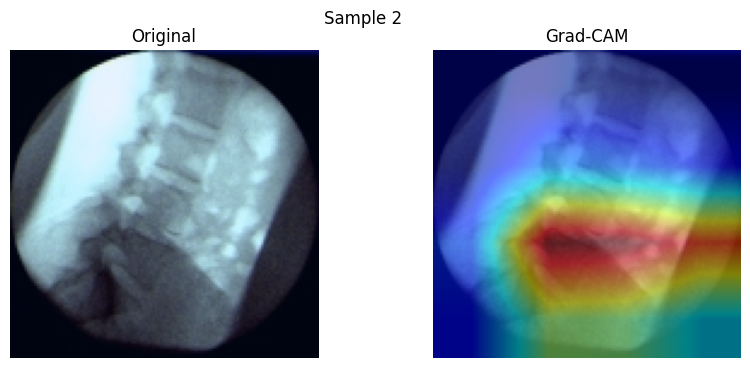

True Sex=0.0                Pred Sex=1.0
True BMI=1.21               Pred BMI=0.16
Loss=1.545


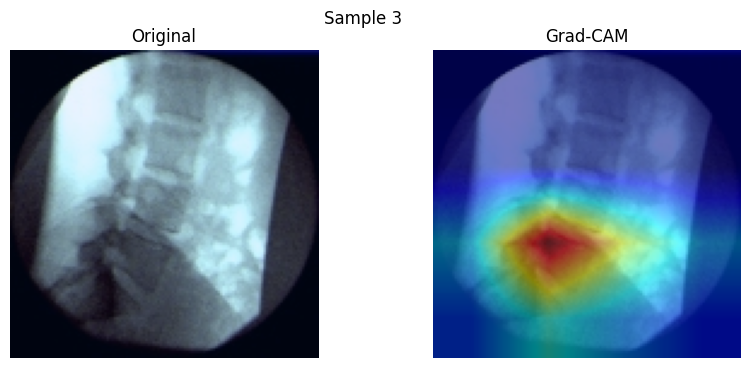

True Sex=0.0                Pred Sex=1.0
True BMI=1.09               Pred BMI=2.05
Loss=1.463


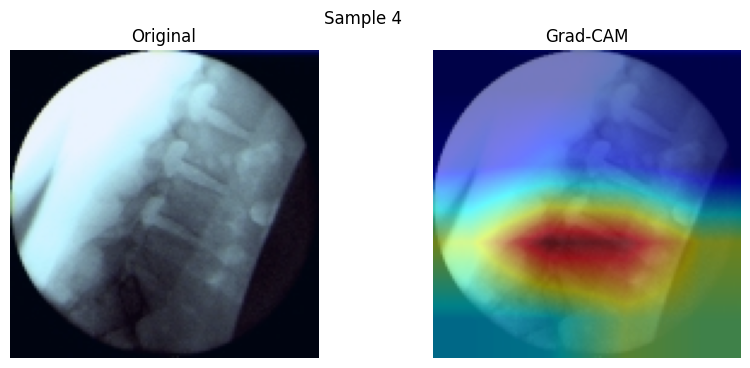

True Sex=0.0                Pred Sex=1.0
True BMI=1.21               Pred BMI=0.32
Loss=1.399


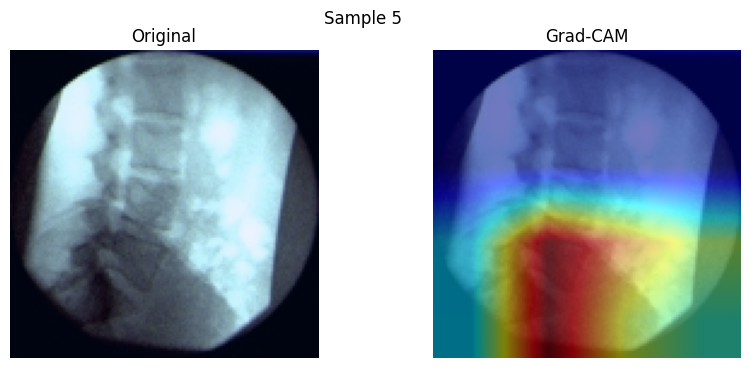

In [ ]:
for idx, sample in enumerate(top5):

    img_tensor = sample['image'].unsqueeze(0).to(device)

    grayscale_cam = cam(
        input_tensor=img_tensor
    )[0]

    img = sample['image'].numpy()

    img = np.transpose(img, (1, 2, 0))

    img_min = img.min()
    img_max = img.max()

    img = (img - img_min) / (img_max - img_min + 1e-8)

    visualization = show_cam_on_image(
        img.astype(np.float32),
        grayscale_cam,
        use_rgb=True
    )
    print(f"True Sex={sample['sex_true']}               " , f"Pred Sex={sample['sex_pred']:.1f}")
    print(f"True BMI={sample['bmi_true']:.2f}              ",  f"Pred BMI={sample['bmi_pred']:.2f}")
    print(f"Loss={sample['loss']:.3f}")
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.imshow(img)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(visualization)
    plt.title("Grad-CAM")
    plt.axis("off")

    plt.suptitle(f"Sample {idx+1}\n")
    plt.show()


###6.3 Fairness
Calculating Mean Absolute Error (MAE) for Female BMI,
Mean Absolute Error (MAE) for Male BMI to find the fairness or bias in sex-related performance .

In [ ]:
model.eval()

all_actual_sex_labels_fairness = []
all_actual_bmi_labels_fairness = []
all_predicted_bmi_fairness = []

# Collect all actual and predicted values from the validation set
with torch.no_grad():
    for images, (sex_labels, bmi_labels) in valid_loader:
        images = images.to(device)
        sex_labels = sex_labels.to(device)
        bmi_labels = bmi_labels.to(device)

        _, bmi_outputs = model(images)

        # Store actual sex and BMI labels
        all_actual_sex_labels_fairness.extend(sex_labels.cpu().numpy())
        all_actual_bmi_labels_fairness.extend(bmi_labels.cpu().numpy())

        # Denormalize predicted BMI values before storing
        predicted_bmi = bmi_outputs.cpu().numpy().flatten()
        denormalized_predicted_bmi = predicted_bmi * bmi_std + bmi_mean
        all_predicted_bmi_fairness.extend(denormalized_predicted_bmi)

# Convert to numpy arrays
all_actual_sex_labels_fairness = np.array(all_actual_sex_labels_fairness)
all_actual_bmi_labels_fairness = np.array(all_actual_bmi_labels_fairness)
all_predicted_bmi_fairness = np.array(all_predicted_bmi_fairness)

# Create masks for female (0) and male (1)
female_mask = (all_actual_sex_labels_fairness == 0)
male_mask = (all_actual_sex_labels_fairness == 1)

# Filter actual and predicted BMI for each sex group
actual_bmi_female = all_actual_bmi_labels_fairness[female_mask]
predicted_bmi_female = all_predicted_bmi_fairness[female_mask]

actual_bmi_male = all_actual_bmi_labels_fairness[male_mask]
predicted_bmi_male = all_predicted_bmi_fairness[male_mask]

# Calculate MAE for each group
mae_female = mean_absolute_error(actual_bmi_female, predicted_bmi_female)
mae_male = mean_absolute_error(actual_bmi_male, predicted_bmi_male)

print(f"Mean Absolute Error (MAE) for Female BMI: {mae_female:.4f}")
print(f"Mean Absolute Error (MAE) for Male BMI: {mae_male:.4f}")

# Interpretation
if abs(mae_female - mae_male) < 0.05: # A small threshold for 'similar'
    print("\nInterpretation: Similar MAE across both groups suggests limited evidence of sex-related performance bias in BMI prediction.")
elif mae_female > mae_male:
    print(f"\nInterpretation: Higher MAE for Female BMI ({mae_female:.4f}) compared to Male BMI ({mae_male:.4f}) suggests potential bias where the model performs worse for females.")
else:
    print(f"\nInterpretation: Higher MAE for Male BMI ({mae_male:.4f}) compared to Female BMI ({mae_female:.4f}) suggests potential bias where the model performs worse for males.")

Mean Absolute Error (MAE) for Female BMI: 24.1662
Mean Absolute Error (MAE) for Male BMI: 22.7985

Interpretation: Higher MAE for Female BMI (24.1662) compared to Male BMI (22.7985) suggests potential bias where the model performs worse for females.


### 6.5 Model Reliability

#### `Strengths:`
*   **Strong Classification Accuracy:** The model demonstrates robust performance in classifying sex, indicating its ability to learn and generalize patterns for this task.
*   **Good BMI Prediction:** The regression head for BMI shows promising results, suggesting the model can effectively estimate continuous values.
*   **Stable Convergence:** The training process exhibits stable convergence, which is crucial for building a reliable and reproducible model.
*   **Transfer Learning Effectiveness:** The use of transfer learning (e.g., with EfficientNet or DenseNet) has proven effective, leveraging pre-trained knowledge to achieve better performance on a relatively small dataset.

#### `Weaknesses:`
*   **Small Dataset:** The limited size of the dataset is a significant weakness, potentially leading to overfitting and hindering generalization to broader populations.
*   **Single Institution Data:** Data collected from a single institution may not be representative of diverse patient populations, limiting the model's applicability in different clinical settings.
*   **Limited BMI Labels:** The discrete nature or limited variability of BMI labels in the dataset could constrain the model's ability to make fine-grained predictions for continuous BMI values.
*   **Observed Overfitting:** Despite regularization techniques, signs of overfitting were observed, indicating that the model might be memorizing training data rather than learning generalizable features.
*   **Performance Degradation on Unseen Populations:** Due to the above limitations, there's a high risk that the model's performance may degrade significantly when deployed on new, unseen patient populations or different imaging protocols.

#### `Sources of Uncertainty:`
*   **Image Quality Variation:** Inconsistent image quality (e.g., resolution, contrast, artifacts) in real-world scenarios can introduce uncertainty and affect model performance.
*   **X-ray Positioning Differences:** Variations in patient positioning during X-ray acquisition can alter anatomical presentation, adding noise and uncertainty to predictions.
*   **Label Noise:** Inaccuracies or inconsistencies in the ground truth labels for sex and BMI can propagate errors during training, leading to an uncertain relationship between features and labels.

## 7. Conclusion



### Project Summary and Key Findings

This project successfully developed a multi-task learning model to predict both sex (classification) and BMI (regression) from X-ray images. Through a systematic experimental approach, starting from a baseline CNN and progressing to a pre-trained EfficientNet backbone with various optimizations, we observed significant improvements in model performance. Key optimizations included data augmentation, refinement of learning rates and weight decay, and crucially, the implementation of 5-Fold Cross-Validation with ensembling of predictions. demonstrating the model's capability to learn relevant features for these tasks.

### Deployment Recommendation

Based on the current analysis, **I would recommend against immediate deployment** of this model in a clinical setting. While the model shows promising performance on the provided dataset and has achieved competitive Kaggle scores, several weaknesses and sources of uncertainty preclude responsible real-world application at this stage:

*   **Small and Single-Institution Dataset:** The model was trained on a relatively small dataset from a single institution. This raises significant concerns about its generalizability to diverse patient populations, different imaging protocols, and varied demographics.
*   **Observed Overfitting:** Despite regularization techniques, signs of overfitting were noted. This suggests the model might be memorizing specific features of the training data rather than learning truly generalizable medical insights.
*   **Limited BMI Label Granularity:** The discretized and sometimes anomalous nature of the BMI labels could limit the model's ability to provide precise continuous BMI predictions.

### Safeguards and Further Testing for Responsible Deployment

1.  **External Validation with Diverse Datasets:** The model must be rigorously tested on a significantly larger and more diverse external dataset, collected from multiple institutions and representing a broader demographic range. This is critical to assess its true generalizability and robustness.
2.  **Robustness Testing:** Evaluate the model's performance under various real-world conditions, including images with varying quality, different X-ray machine parameters, and patient positioning differences.
3.  **Comprehensive Fairness Analysis:** Extend the fairness analysis beyond basic sex-based MAE. Investigate potential biases across other demographic groups (e.g., age, ethnicity, different disease states) and ensure equitable performance.
4.  **Clinical Expert Review:** Integrate clinical expertise to interpret Grad-CAM visualizations and ensure that the features the model focuses on are medically relevant and make clinical sense.
5.  **Uncertainty Quantification:** Implement methods to quantify the model's uncertainty in its predictions, especially for critical medical decisions, to provide clinicians with a clearer understanding of prediction reliability.


## Predictions for the test set

In [ ]:
model.eval()  # Set the model to evaluation mode
hold_out_sex_pred = []
hold_out_bmi_pred = []

with torch.no_grad():
    for images, _ in test_loader: # test_loader does not have labels (only placeholder -1.0 for sex/bmi)
        images = images.to(device)
        sex_outputs, bmi_outputs = model(images) # Get both sex and bmi outputs

        # Process sex predictions (binary classification)
        predicted_sex = (torch.sigmoid(sex_outputs) > 0.5).float().cpu().numpy()
        hold_out_sex_pred.extend(predicted_sex.flatten().tolist())

        # Process BMI predictions (regression)
        predicted_bmi = bmi_outputs.cpu().numpy() # No thresholding for regression
        predicted_bmi = predicted_bmi * bmi_std + bmi_mean
        hold_out_bmi_pred.extend(predicted_bmi.flatten().tolist())

hold_out_sex_pred = np.array(hold_out_sex_pred)
hold_out_bmi_pred = np.array(hold_out_bmi_pred).round(3)

# Get the filenames for the test set from the DataFrame used to create test_ds
hold_out_filenames = test_df_data['filename'].tolist()



# Create a DataFrame for submission
submission_df = pd.DataFrame({'filename': hold_out_filenames, 'sex': hold_out_sex_pred, 'bmi': hold_out_bmi_pred})

# Kaggle submission requires the header and index=False
submission_df.to_csv('submission.csv', index=False)

print("Submission file created successfully!")
print(submission_df.head())

Submission file created successfully!
        filename  sex     bmi
0  5580_3270.jpg  0.0  25.658
1  4658_6855.jpg  0.0  27.293
2  8152_4582.jpg  1.0  22.314
3  3272_2254.jpg  1.0  23.486
4  1590_4958.jpg  0.0  24.251


In [ ]:
print(submission_df['sex'].value_counts())
#print(submission_df['bmi'].unique())
print(submission_df['bmi'].value_counts())
submission_df.describe()
print(len(submission_df['bmi']))

sex
0.0    117
1.0     78
Name: count, dtype: int64
bmi
22.368    2
24.782    2
25.658    1
23.486    1
27.293    1
         ..
23.886    1
22.056    1
25.347    1
23.151    1
20.218    1
Name: count, Length: 193, dtype: int64
195


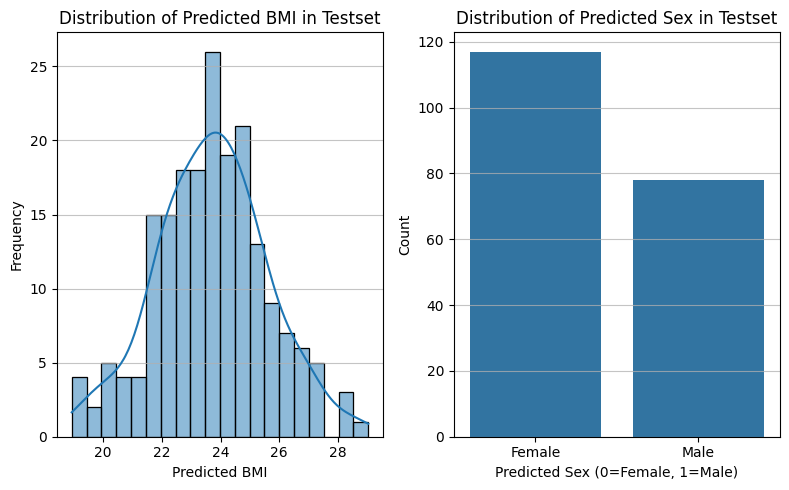

In [ ]:
plt.figure(figsize=(8, 5))

# Plot for Predicted BMI Distribution
plt.subplot(1, 2, 1) # 1 row, 2 columns, first plot
sns.histplot(submission_df['bmi'], kde=True, bins=20)
plt.title('Distribution of Predicted BMI in Testset')
plt.xlabel('Predicted BMI')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.75)

# Plot for Predicted Sex Distribution
plt.subplot(1, 2, 2) # 1 row, 2 columns, second plot
sns.countplot(x=submission_df['sex'])
plt.title('Distribution of Predicted Sex in Testset')
plt.xlabel('Predicted Sex (0=Female, 1=Male)')
plt.ylabel('Count')
plt.grid(axis='y', alpha=0.75)
plt.xticks([0, 1], ['Female', 'Male'])

plt.tight_layout()
plt.show()